# Ski-jump flight: solver and experiments

Seo, Murakami & Yoshida (2004) model, six coupled ODEs integrated with RK4.

- **The model lives in `make_plots.py`** (one source of truth). This notebook imports it.
- **Aerodynamics** come from `tomaz_aerodynamics.py` (+ its CSV), in the same folder.
- **Experiments:** jump to section 5 and change the values there.

Still placeholders: mass `m`, inertia `I`, air density `rho`, and the hill profile (an approximation of Okurayama).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

import make_plots as mp 

## 1. RK4 on a toy problem

dx/dt = −x, x(0) = 1, so x(1) = e⁻¹ exactly. Halving the step should cut the error about 16×.

In [2]:
def f_toy(t, x):
    return -x

for h in [0.1, 0.05, 0.025]:
    t, x = 0.0, 1.0
    while t < 1.0 - 1e-12:
        x = mp.rk4_step(f_toy, t, x, h)
        t += h
    print(f"h = {h:<6}  error = {abs(x - np.exp(-1)):.3e}")

h = 0.1     error = 3.332e-07
h = 0.05    error = 1.998e-08
h = 0.025   error = 1.223e-09


## 2. Validation without air

No lift, drag or moment, so the path must be the exact parabola, and the landing on a straight 35° hill is known exactly. The landing error should fall with slope 4.

fitted order p = 4.00 (RK4: 4),  max position error = 1.2e-07 m


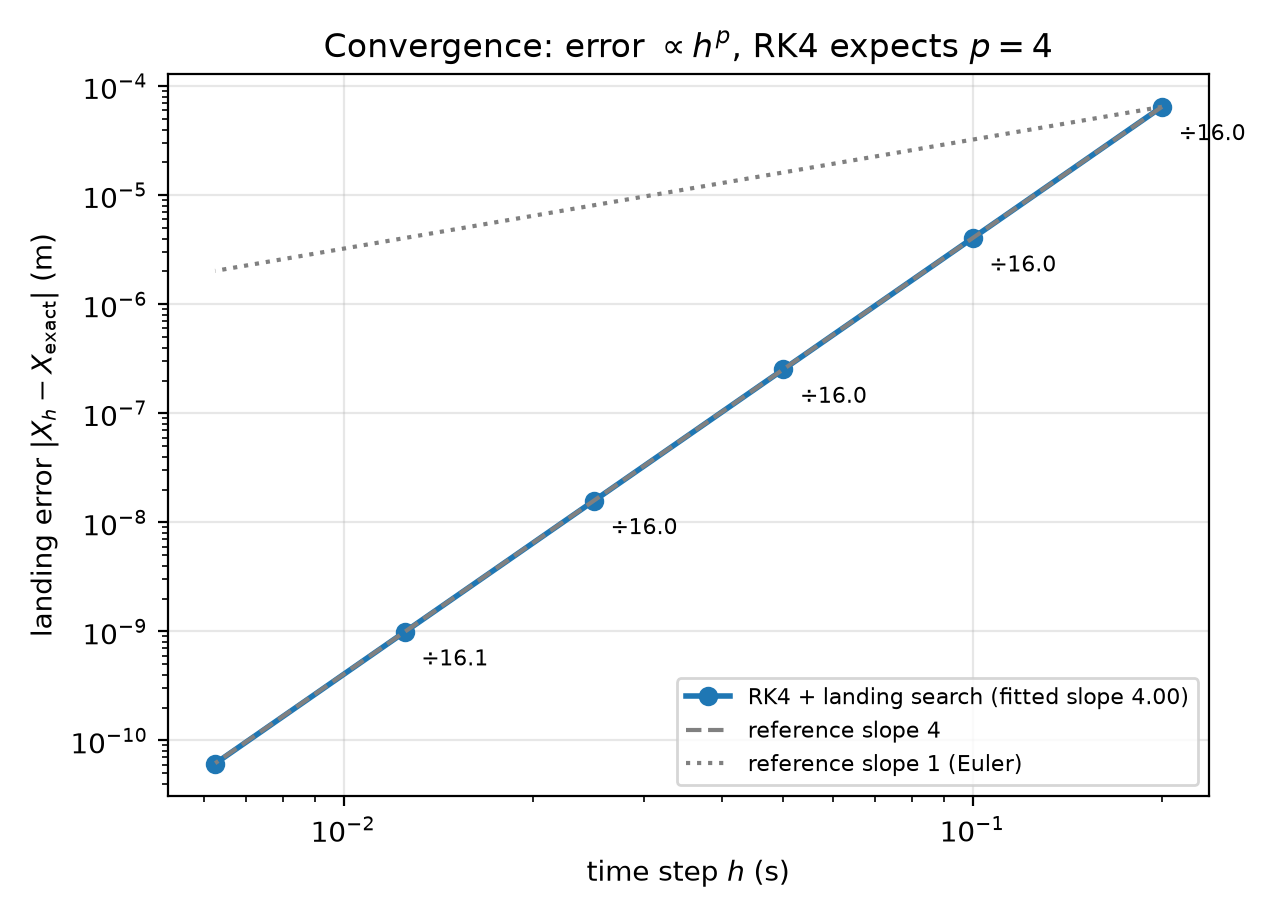

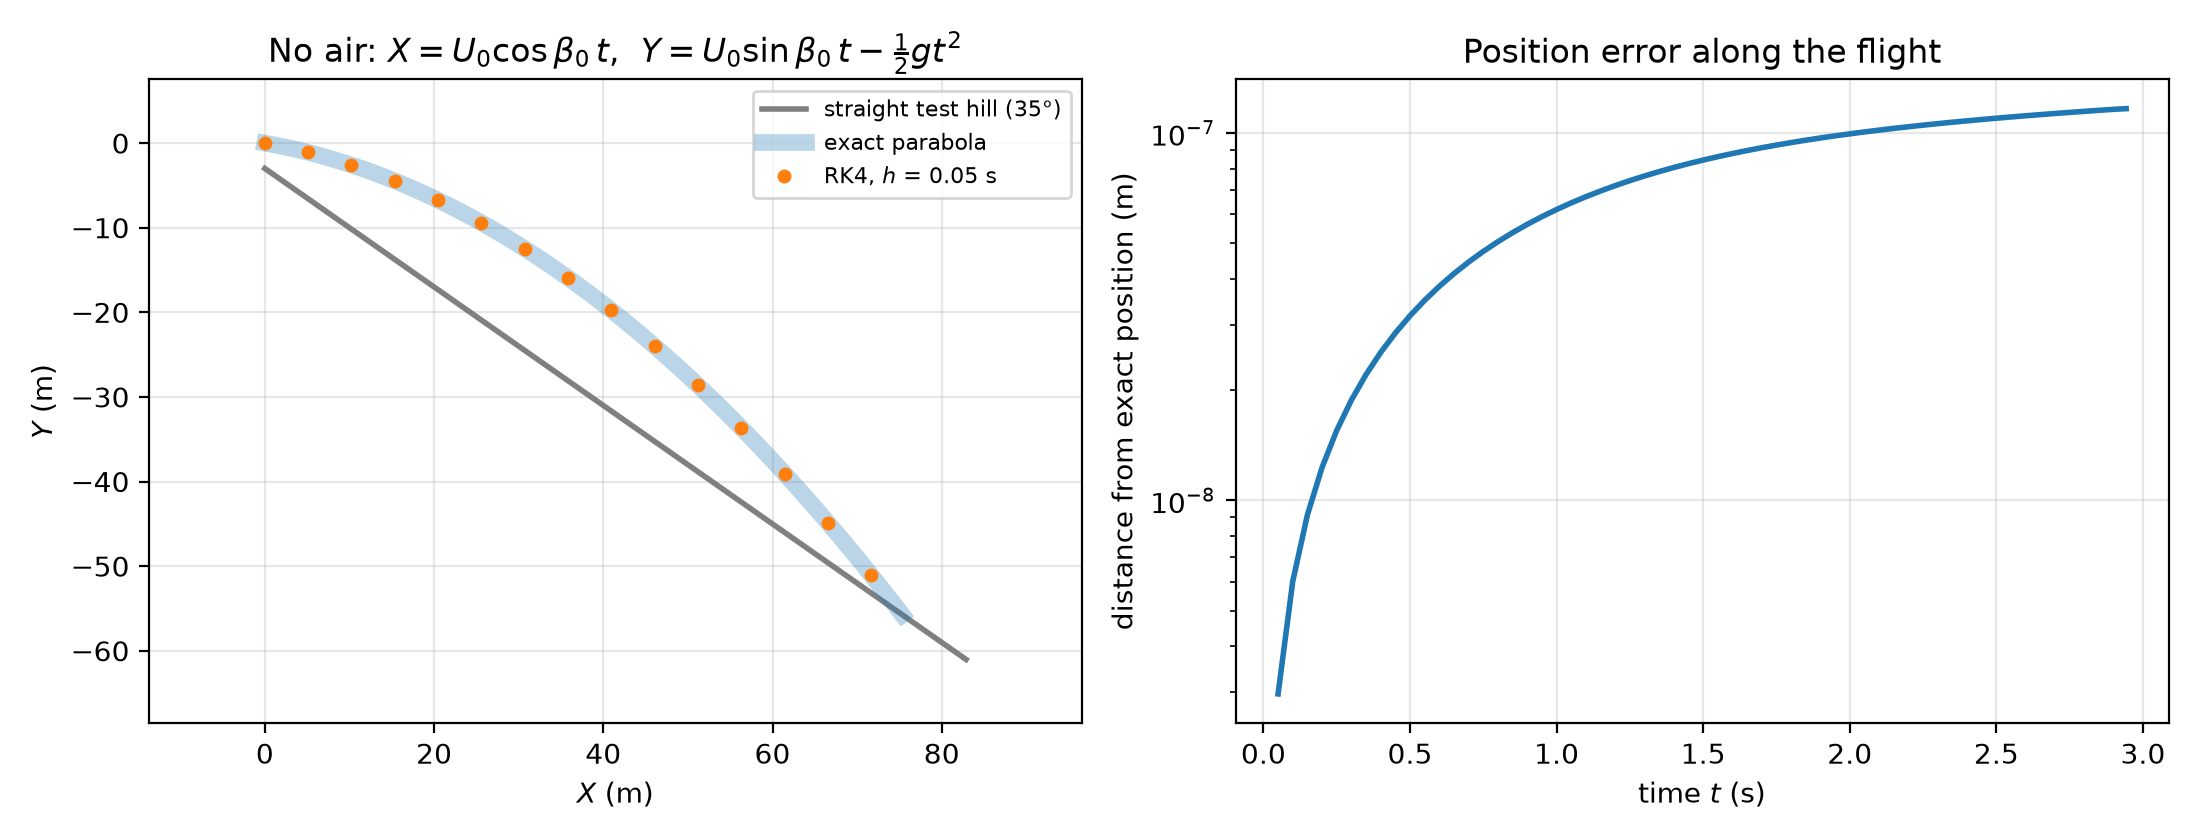

In [3]:
p, hs, errs = mp.fig_convergence()
max_err = mp.fig_validation()
print(f"fitted order p = {p:.2f} (RK4: 4),  max position error = {max_err:.1e} m")
display(Image("figures/fig1_convergence.png"))
display(Image("figures/fig2_validation.png"))

## 3. Reference jump

Fixed posture θ = 7°, λ = 25°, no wind, starting from the paper's state 0.4 s after take-off. Paper: about 131 m.

landing X        151.3 m   (paper: 131 m)
along the hill   178.7 m
flight time      5.72 s since take-off
alpha            14.7 to 29.2 deg


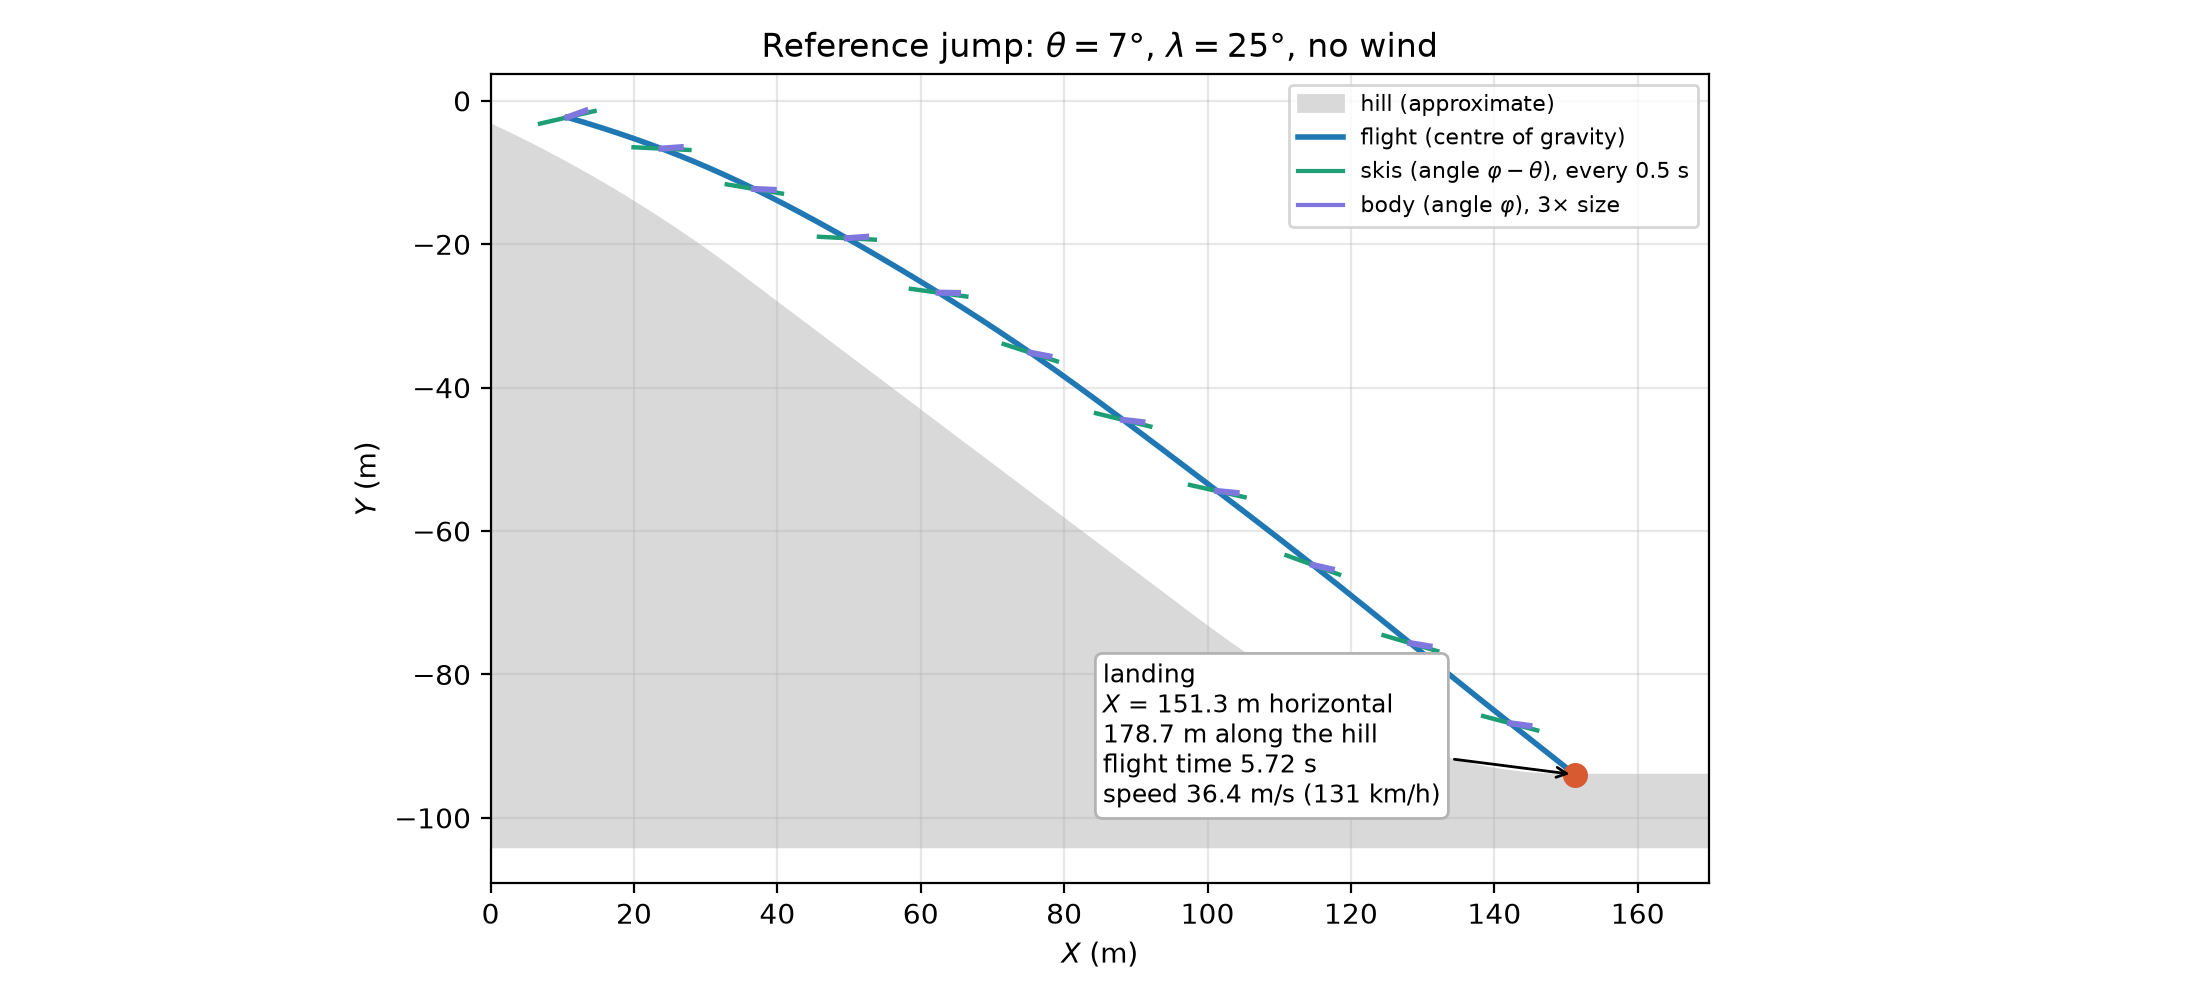

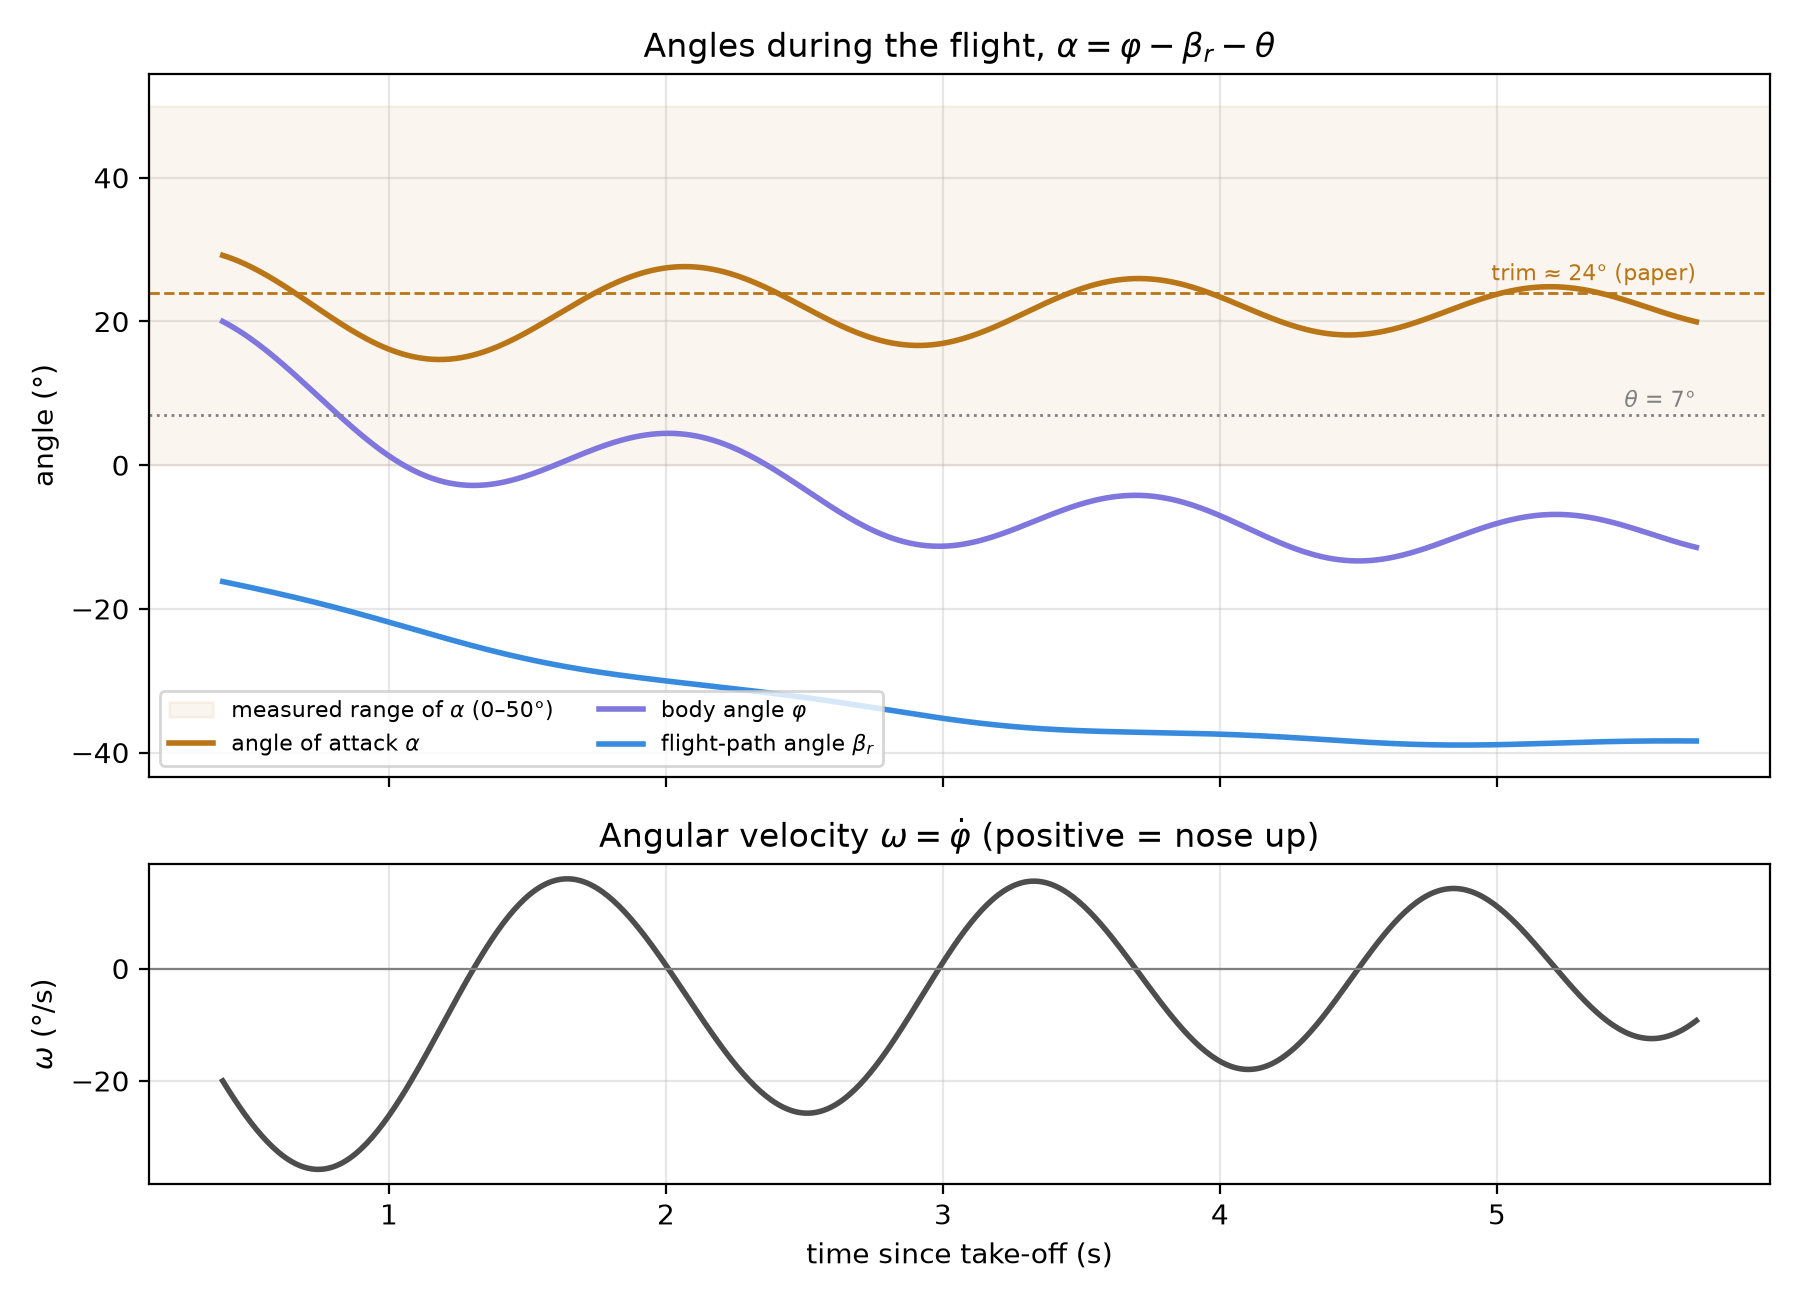

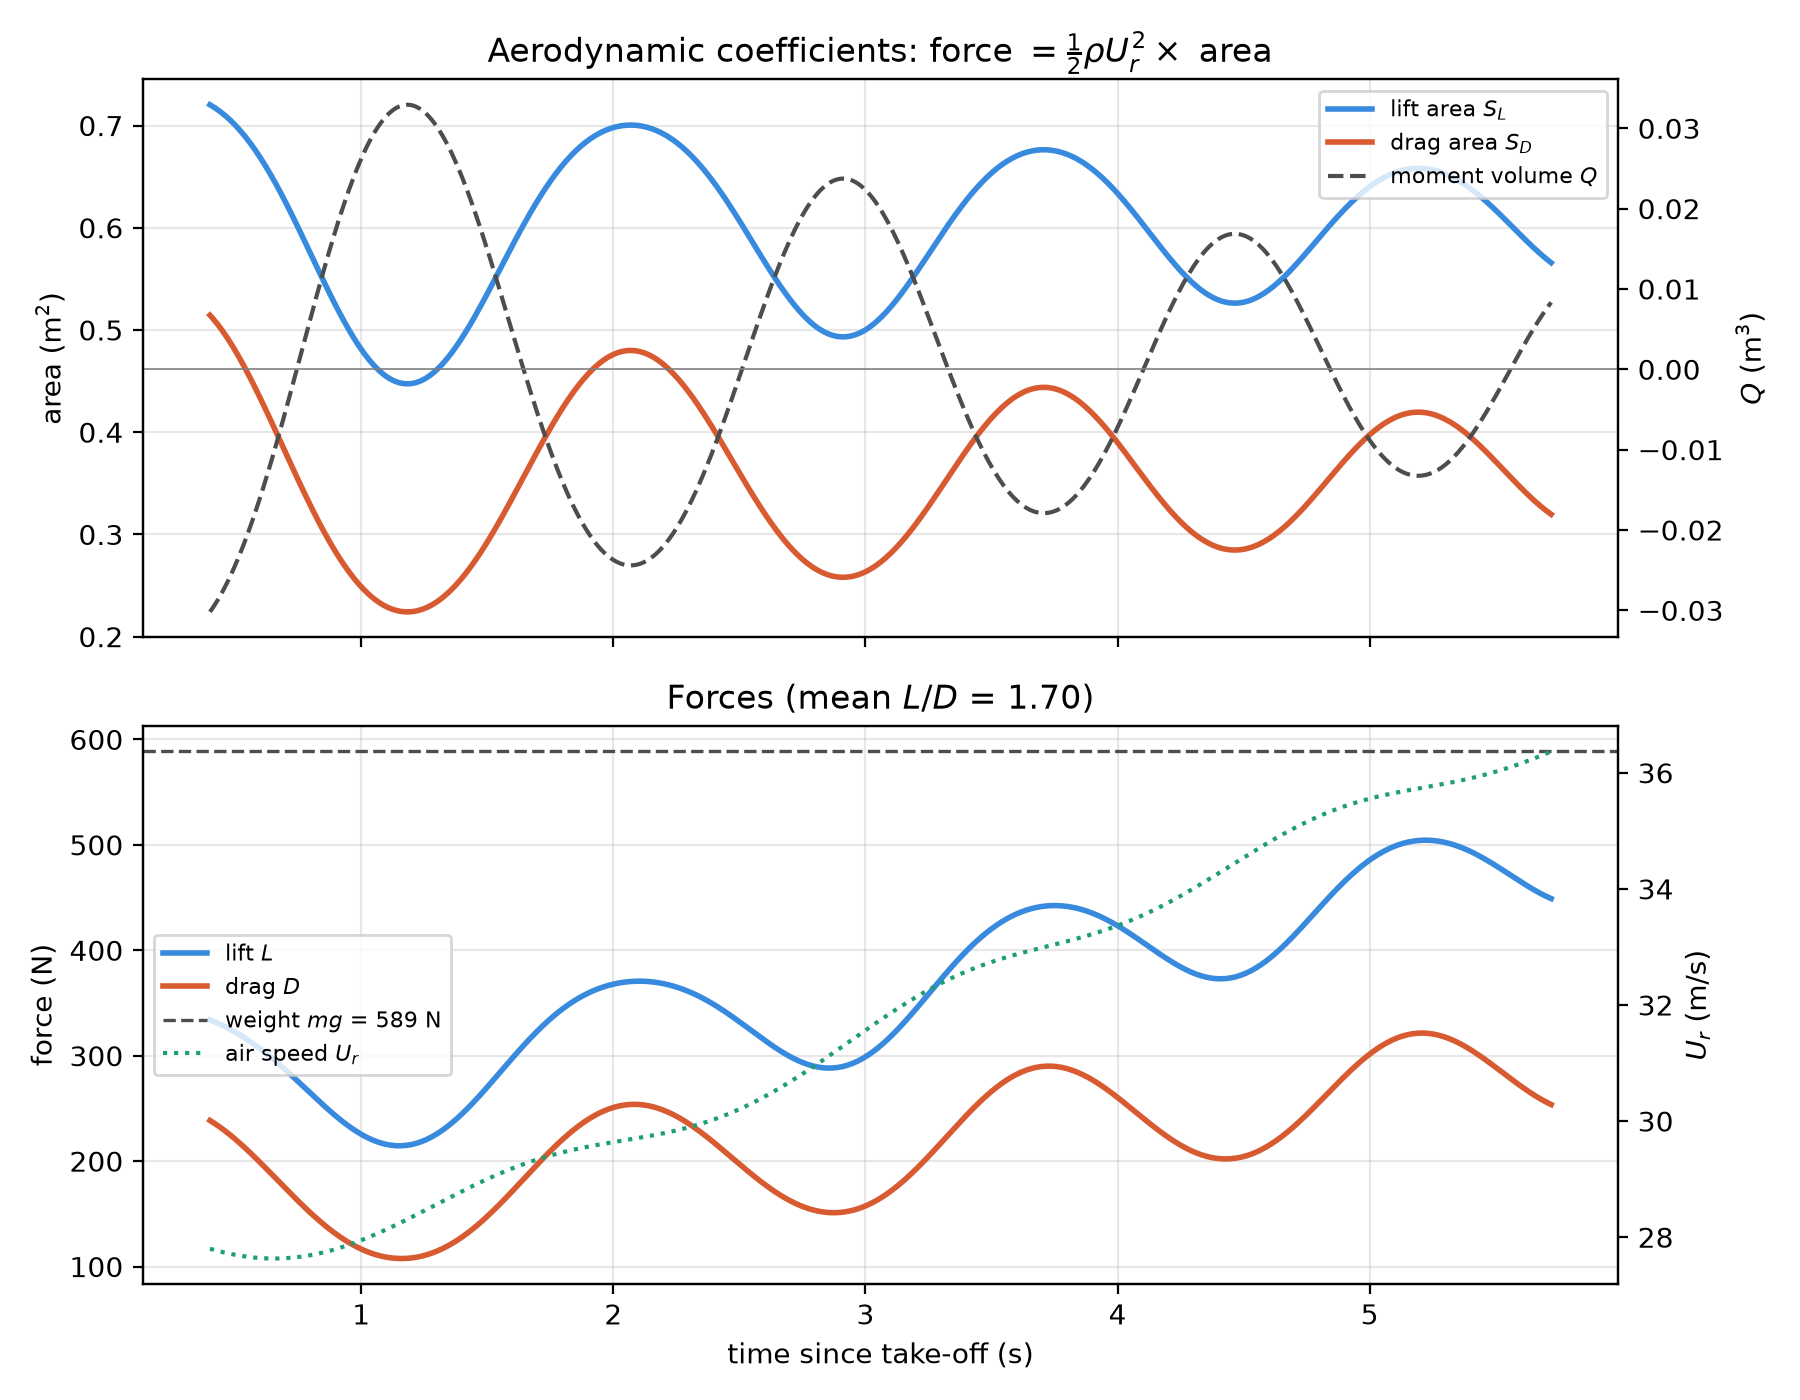

In [4]:
ts, path = mp.simulate(mp.make_f(), mp.start_state(0.0), 0.01, mp.hill)
d = mp.diagnostics(path)

X_land = path[-1, 0]
print(f"landing X        {X_land:.1f} m   (paper: 131 m)")
print(f"along the hill   {mp.along_hill(X_land):.1f} m")
print(f"flight time      {ts[-1] + mp.T0:.2f} s since take-off")
print(f"alpha            {np.degrees(d['alpha']).min():.1f} to {np.degrees(d['alpha']).max():.1f} deg")

mp.fig_flight(ts, path, d); mp.fig_angles(ts, path, d); mp.fig_forces(ts, path, d)
for name in ("fig3_flight", "fig4_angles", "fig5_forces"):
    display(Image(f"figures/{name}.png"))

## 4. Time-step convergence on the full model

No exact answer here, so compare each run with the previous one: the change should shrink fast.

In [5]:
prev = None
for h in [0.1, 0.05, 0.025, 0.0125]:
    _, p_h = mp.simulate(mp.make_f(), mp.start_state(0.0), h, mp.hill)
    X = p_h[-1, 0]
    change = abs(X - prev) if prev is not None else float("nan")
    print(f"h = {h:<7} X = {X:.6f} m   change = {change:.2e}")
    prev = X

h = 0.1     X = 151.265221 m   change = nan
h = 0.05    X = 151.264872 m   change = 3.49e-04
h = 0.025   X = 151.264862 m   change = 9.47e-06
h = 0.0125  X = 151.264862 m   change = 1.81e-07


## 5. Experiments (change things here)

`mp.landing(theta, lam, W)` runs one full jump and returns the horizontal landing X. Angles in **radians**, wind in m/s (**positive = tail wind**).

The measured wind-tunnel range is θ 0–40° and λ 0–25°; outside it the aero fit is extrapolating.

To change a global setting for every run, assign it on the module, e.g. `mp.m = 70.0`.

In [6]:
theta = np.radians(7)
lam   = np.radians(25)
W     = 0.0

print(f"landing X = {mp.landing(theta=theta, lam=lam, W=W):.1f} m")

landing X = 151.3 m


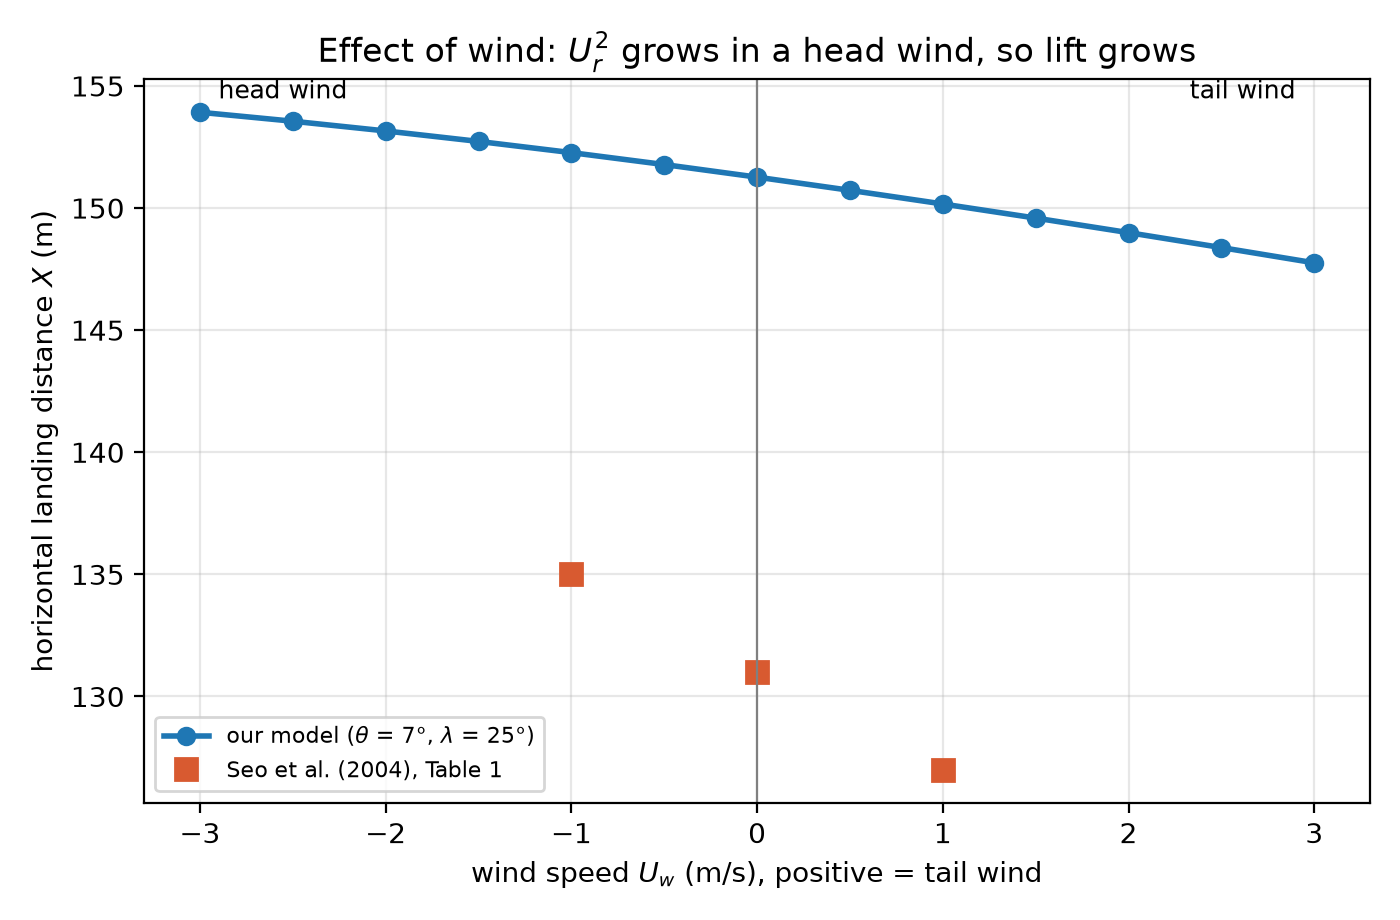

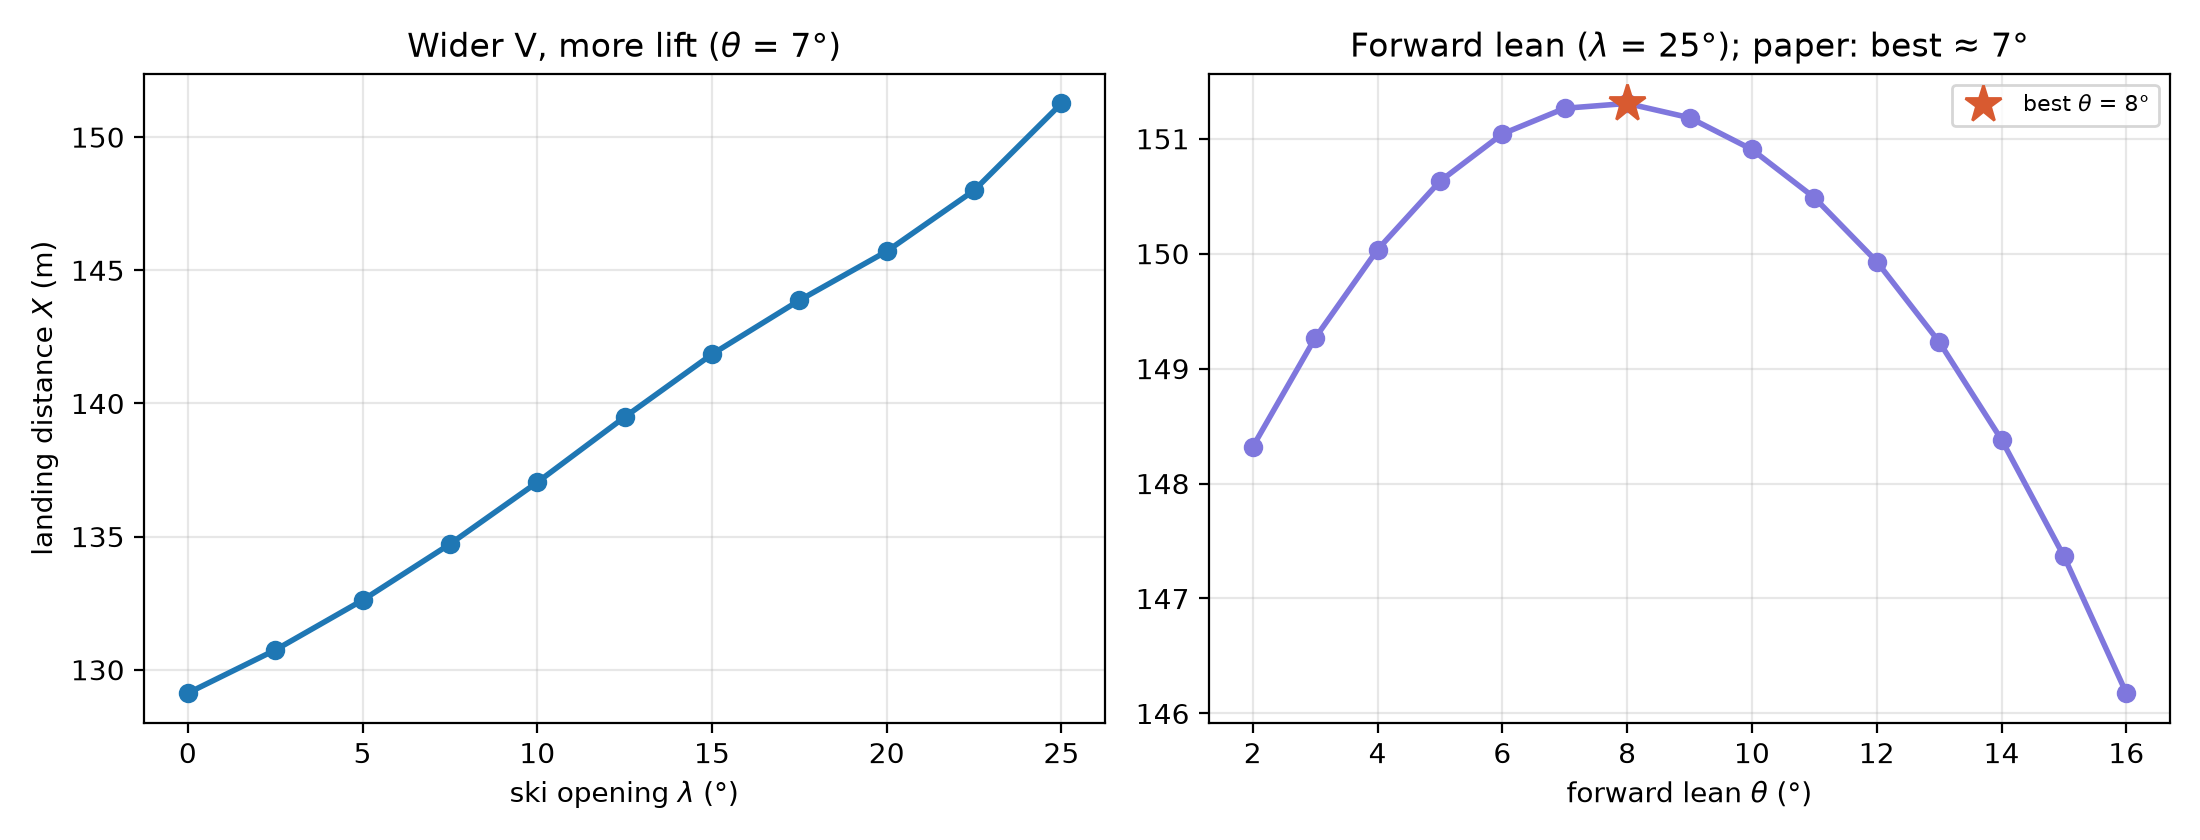

In [7]:
mp.fig_wind(); mp.fig_posture()
display(Image("figures/fig6_wind.png"))
display(Image("figures/fig7_posture.png"))

### 5.1 Grid search over posture (first step of the optimisation)

Every (θ, λ) pair is one full simulation. A coarse grid takes a minute or so; refine around the best point afterwards.

best on this grid: theta = 8 deg, lambda = 25.0 deg, X = 151.3 m


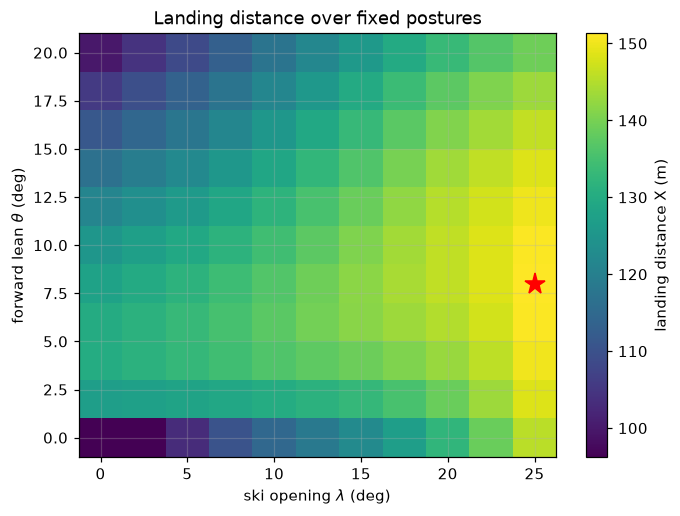

In [9]:
thetas = np.arange(0, 21, 2)     
lams   = np.arange(0, 26, 2.5)

grid = np.array([[mp.landing(theta=np.radians(t), lam=np.radians(l)) for l in lams]
                 for t in thetas])

i, j = np.unravel_index(np.nanargmax(grid), grid.shape)
print(f"best on this grid: theta = {thetas[i]} deg, lambda = {lams[j]} deg, X = {grid[i, j]:.1f} m")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.pcolormesh(lams, thetas, grid, shading="nearest", cmap="viridis")
ax.plot(lams[j], thetas[i], "r*", ms=14)
fig.colorbar(im, label="landing distance X (m)")
ax.set_xlabel(r"ski opening $\lambda$ (deg)"); ax.set_ylabel(r"forward lean $\theta$ (deg)")
ax.set_title("Landing distance over fixed postures")
plt.show()

## Open questions

- **Distance too long:** 151 m against the paper's 131 m, most likely the placeholder `m`, `I` and hill.
- **Wind effect too small:** about 0.5 m per 1 m/s, against about 4 m in the paper. The direction is right (head wind longer).
- **Next for the optimisation:** posture that changes during the flight (the paper gets 139 m by varying λ).